# Explore the Dataversity survey responses

Load the CSV into a pandas DataFrame, inspect its columns and missing values, then use the examples below as a starting point for filtering and summarizing responses.

In [98]:
from pathlib import Path
from textwrap import fill

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from scipy.stats import f as f_distribution
from scipy.stats import f_oneway, fisher_exact, spearmanr

from mast_toolkit_notebooks.utils import (
    display_original_correlations,
    parse_choices,
    plot_positive_metrics_by_category,
)

PROJECT_NAME = "dataversity-2026"
data_dir = Path("data") / PROJECT_NAME
if not data_dir.exists():
    data_dir = Path("../data") / PROJECT_NAME

responses_file = data_dir / "dataversity_survey_2iyUvU5Z4Pdi25fBvXwQsJ_responses.csv"
metadata_file = data_dir / "dataversity_metadata.csv"

responses = pd.read_csv(responses_file)
metadata = pd.read_csv(metadata_file)
metadata["choices_parsed"] = metadata["choices (if applicable)"].apply(parse_choices)
print(f"Loaded {len(responses):,} responses from {responses_file}")
print(
    f"Loaded metadata for {len(metadata)} fields; "
    f"{metadata['choices_parsed'].str.len().gt(0).sum()} fields have choices."
)

Loaded 178 responses from ../data/dataversity-2026/dataversity_survey_2iyUvU5Z4Pdi25fBvXwQsJ_responses.csv
Loaded metadata for 40 fields; 28 fields have choices.


In [99]:
# Inspect the table before transforming it
print("Shape:", responses.shape)
print("Columns:", responses.columns.tolist())
responses.info()

missing_by_column = responses.isna().sum().sort_values(ascending=False)
display(missing_by_column[missing_by_column > 0].to_frame("missing values"))

Shape: (178, 40)
Columns: ['id', 'team', 'response_date', 'is_complete', 'tools', 'industry', 'number_of_employees', 'job_category', 'geography', 'other_data_activity', 'data_used_or_created', 'beliefs_metadata_1', 'beliefs_metadata_2', 'beliefs_analysis_1', 'beliefs_analysis_2', 'beliefs_standards_1', 'beliefs_standards_2', 'beliefs_teamwork_1', 'beliefs_teamwork_2', 'actions_inventory_1', 'actions_inventory_2', 'actions_inventory_qual', 'actions_document_1', 'actions_document_2', 'actions_document_qual', 'actions_endorse_1', 'actions_endorse_2', 'actions_endorse_qual', 'actions_audit_1', 'actions_audit_2', 'actions_audit_qual', 'actions_leadership_1', 'actions_leadership_2', 'actions_leadership_qual', 'self_assess_value', 'self_assess_trust', 'self_assess_secure', 'ai_readiness', 'ai_results', 'ai_responsibility']
<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 40 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------             

,missing values
team,178
data_used_or_created,178
actions_audit_qual,167
actions_leadership_qual,167
actions_endorse_qual,166
other_data_activity,163
actions_document_qual,151
actions_inventory_qual,146
tools,136
industry,57


# Preprocessing

Add an analysis column for action metrics that prevents analysis on option "1" which is the "i dont do this" column.


In [100]:
# Work on a copy so the original imported data stays unchanged.
analysis_df = responses.copy()

# Recode ratings for display while retaining their numeric source columns.
NEGATIVE = [1, 2]
NEUTRAL = [3]
POSITIVE = [4, 5]
DONT_KNOW = 9
recode_map = {
    **{value: "negative" for value in NEGATIVE},
    **{value: "neutral" for value in NEUTRAL},
    **{value: "positive" for value in POSITIVE},
    DONT_KNOW: "don't know",
}

analysis_df["response_date"] = pd.to_datetime(analysis_df["response_date"], errors="coerce", utc=True)

rating_columns = [
    column
    for column in analysis_df.columns
    if column.startswith(("beliefs_", "actions_", "self_assess_", "ai_"))
    and not column.endswith(("_qual", "_recoded", "_excluding_1"))
]
analysis_df[rating_columns] = analysis_df[rating_columns].apply(pd.to_numeric, errors="coerce")

action_columns = [column for column in rating_columns if column.startswith("actions_")]
action_analysis_columns = {
    column: f"{column}_excluding_1" for column in action_columns
}
for column, analysis_column in action_analysis_columns.items():
    analysis_df[analysis_column] = analysis_df[column].mask(analysis_df[column].eq(1))

recode_columns = [
    column
    for column in rating_columns
    if column.startswith(("beliefs_", "self_assess_", "ai_"))
]
for column in recode_columns:
    analysis_df[f"{column}_recoded"] = analysis_df[column].map(recode_map)

display(analysis_df[[*action_columns[:2], *[action_analysis_columns[column] for column in action_columns[:2]]]].head())
display(analysis_df[[*recode_columns, *[f"{column}_recoded" for column in recode_columns]]].head())

# Example: filter to completed responses and count them by industry.
completed = analysis_df.loc[
    analysis_df["is_complete"].astype("string").str.casefold().eq("true")
]
display(completed["industry"].value_counts(dropna=False).head(10).to_frame("responses"))

,actions_inventory_1,actions_inventory_2,actions_inventory_1_excluding_1,actions_inventory_2_excluding_1
0,2.0,2.0,2.0,2.0
1,NaN,NaN,NaN,NaN
2,5.0,5.0,5.0,5.0
3,NaN,NaN,NaN,NaN
4,4.0,4.0,4.0,4.0


,beliefs_metadata_1,beliefs_metadata_2,beliefs_analysis_1,beliefs_analysis_2,beliefs_standards_1,beliefs_standards_2,beliefs_teamwork_1,beliefs_teamwork_2,self_assess_value,self_assess_trust,...,beliefs_standards_1_recoded,beliefs_standards_2_recoded,beliefs_teamwork_1_recoded,beliefs_teamwork_2_recoded,self_assess_value_recoded,self_assess_trust_recoded,self_assess_secure_recoded,ai_readiness_recoded,ai_results_recoded,ai_responsibility_recoded
0,4,2,2,1,2,2,2,3,4,3,...,negative,negative,negative,neutral,positive,neutral,positive,negative,neutral,negative
1,3,4,5,5,3,3,3,5,5,2,...,neutral,neutral,neutral,positive,positive,negative,neutral,positive,positive,neutral
2,4,3,4,4,4,3,4,4,5,4,...,positive,neutral,positive,positive,positive,positive,positive,neutral,positive,neutral
3,4,4,4,4,4,4,4,4,4,4,...,positive,positive,positive,positive,positive,positive,positive,positive,positive,positive
4,5,4,4,4,4,3,4,5,4,4,...,positive,neutral,positive,positive,positive,positive,positive,positive,negative,don't know


,responses
industry,
Government,22
Banking,15
Finance,14
Healthcare,10
Utilities,10
Education,9
Technology,8
Insurance,8
Energy,5


## Pairwise Spearman correlations across belief, action, self-assessment and AI variables

Each cell shows Spearman's rho with its unadjusted p-value for completed responses, using pairwise deletion of missing values. The **unadjusted** matrices use the original ratings (including "don't know" `9` and action rating `1`). The **adjusted** matrices treat `9` as missing and exclude action rating `1` ("I don't do this").

Cells with p < 0.05 are shaded by |rho|: > 0.35 (lightest), > 0.45, > 0.55, > 0.65 and > 0.75 (darkest).

In [101]:
from itertools import combinations

pairwise_columns = [
    column
    for column in rating_columns
    if column.startswith(("beliefs_", "actions_", "self_assess_", "ai_"))
]
beliefs_columns = [column for column in pairwise_columns if column.startswith("beliefs_")]
action_rows = [column for column in pairwise_columns if column.startswith("actions_")]
ai_outcome_columns = [column for column in pairwise_columns if column.startswith("ai_")]
self_assess_columns = [column for column in pairwise_columns if column.startswith("self_assess_")]

# Unadjusted: original numeric values, so 9 ("don't know") and action 1 ("I don't do this") stay in.
unadjusted_data = completed[pairwise_columns]

# Adjusted: 9 becomes missing, and action ratings use the *_excluding_1 columns.
adjusted_data = (
    completed[[action_analysis_columns.get(column, column) for column in pairwise_columns]]
    .set_axis(pairwise_columns, axis=1)
    .replace(DONT_KNOW, float("nan"))
)


def spearman_matrices(data):
    rho = pd.DataFrame(float("nan"), index=data.columns, columns=data.columns)
    p_values = rho.copy()
    for left, right in combinations(data.columns, 2):
        pair = data[[left, right]].dropna()  # pairwise deletion of missing values
        if len(pair) > 2 and pair[left].nunique() > 1 and pair[right].nunique() > 1:
            result = spearmanr(pair[left], pair[right])
            rho.loc[left, right] = rho.loc[right, left] = result.statistic
            p_values.loc[left, right] = p_values.loc[right, left] = result.pvalue
    return rho, p_values


def format_matrix(rho, p_values):
    cells = pd.DataFrame("n/a", index=rho.index, columns=rho.columns)
    for row in rho.index:
        for column in rho.columns:
            if row == column:
                cells.loc[row, column] = "—"
            elif pd.notna(rho.loc[row, column]):
                cells.loc[row, column] = (
                    f"{rho.loc[row, column]:.2f} (p={p_values.loc[row, column]:.3g})"
                )
    return cells


# (minimum |rho|, background colour), strongest first
RHO_COLOUR_STEPS = [
    (0.65, "#90edff"),
    (0.55, "#5ffb67"),
    (0.45, "#ccf95b"),
    # (0.35, "#ffc71e"),
    (0.35, "#fff2c9"),
]
ALPHA = 0.05


def cell_style(rho_value, p_value):
    if pd.isna(rho_value) or p_value >= ALPHA:
        return ""
    for min_rho, colour in RHO_COLOUR_STEPS:
        if abs(rho_value) > min_rho:
            return f"background-color: {colour} !important; color: #000 !important;"
    return ""


def style_matrix(rho, p_values):
    styles = rho.copy().astype(object)
    for row in rho.index:
        for column in rho.columns:
            styles.loc[row, column] = cell_style(rho.loc[row, column], p_values.loc[row, column])
    return format_matrix(rho, p_values).style.apply(lambda _: styles, axis=None)


unadjusted_rho, unadjusted_p = spearman_matrices(unadjusted_data)
adjusted_rho, adjusted_p = spearman_matrices(adjusted_data)


def show_matrices(rows, columns):
    display(Markdown("#### Unadjusted: Spearman rho (p-value)"))
    display(style_matrix(
        unadjusted_rho.loc[rows, columns], unadjusted_p.loc[rows, columns]
    ))
    display(Markdown("#### Adjusted: Spearman rho (p-value), excluding \"don't know\" and action rating 1"))
    display(style_matrix(
        adjusted_rho.loc[rows, columns], adjusted_p.loc[rows, columns]
    ))

### AI outcomes (columns) vs beliefs and actions (rows)

In [102]:
show_matrices(
    rows=[*beliefs_columns, *action_rows],
    columns=(ai_outcome_columns+self_assess_columns),
)

#### Unadjusted: Spearman rho (p-value)

,ai_readiness,ai_results,ai_responsibility,self_assess_value,self_assess_trust,self_assess_secure
beliefs_metadata_1,0.36 (p=6.01e-05),0.37 (p=2.87e-05),0.44 (p=4.36e-07),0.63 (p=7.34e-15),0.46 (p=1.09e-07),0.35 (p=9.38e-05)
beliefs_metadata_2,0.36 (p=5.55e-05),0.28 (p=0.00155),0.30 (p=0.000892),0.41 (p=2.61e-06),0.45 (p=3e-07),0.26 (p=0.00354)
beliefs_analysis_1,0.47 (p=6.3e-08),0.39 (p=1.14e-05),0.39 (p=8.65e-06),0.65 (p=1.25e-15),0.50 (p=4.05e-09),0.33 (p=0.000227)
beliefs_analysis_2,0.49 (p=1.17e-08),0.41 (p=3.76e-06),0.33 (p=0.000241),0.54 (p=2.49e-10),0.53 (p=3.75e-10),0.30 (p=0.000952)
beliefs_standards_1,0.44 (p=3.51e-07),0.32 (p=0.000282),0.34 (p=0.000172),0.65 (p=4.23e-16),0.48 (p=2.73e-08),0.24 (p=0.00687)
beliefs_standards_2,0.46 (p=9.22e-08),0.36 (p=6.28e-05),0.41 (p=2.79e-06),0.54 (p=1.65e-10),0.55 (p=4.95e-11),0.27 (p=0.00249)
beliefs_teamwork_1,0.45 (p=2.85e-07),0.35 (p=7.37e-05),0.44 (p=5.86e-07),0.54 (p=2.43e-10),0.39 (p=1.08e-05),0.28 (p=0.00194)
beliefs_teamwork_2,0.33 (p=0.000248),0.27 (p=0.00278),0.34 (p=0.00016),0.39 (p=8.19e-06),0.51 (p=1.87e-09),0.39 (p=1.25e-05)
actions_inventory_1,0.20 (p=0.0316),0.17 (p=0.0604),0.18 (p=0.0525),0.25 (p=0.0048),0.27 (p=0.00238),0.08 (p=0.355)
actions_inventory_2,0.09 (p=0.329),0.09 (p=0.312),0.10 (p=0.266),0.16 (p=0.0716),0.24 (p=0.00905),0.22 (p=0.016)


#### Adjusted: Spearman rho (p-value), excluding "don't know" and action rating 1

,ai_readiness,ai_results,ai_responsibility,self_assess_value,self_assess_trust,self_assess_secure
beliefs_metadata_1,0.34 (p=0.000221),0.36 (p=0.00011),0.48 (p=1.51e-07),0.64 (p=9.35e-15),0.47 (p=6.31e-08),0.32 (p=0.000389)
beliefs_metadata_2,0.32 (p=0.000586),0.22 (p=0.0186),0.29 (p=0.00227),0.38 (p=1.84e-05),0.43 (p=1.21e-06),0.25 (p=0.0065)
beliefs_analysis_1,0.41 (p=8.18e-06),0.32 (p=0.000532),0.37 (p=9e-05),0.63 (p=1.42e-14),0.49 (p=1.77e-08),0.31 (p=0.000572)
beliefs_analysis_2,0.48 (p=6.51e-08),0.39 (p=2.07e-05),0.34 (p=0.00029),0.52 (p=1.74e-09),0.54 (p=3.02e-10),0.28 (p=0.002)
beliefs_standards_1,0.42 (p=3.35e-06),0.33 (p=0.000378),0.36 (p=0.000114),0.64 (p=8.16e-15),0.48 (p=3.11e-08),0.25 (p=0.00627)
beliefs_standards_2,0.39 (p=2.15e-05),0.33 (p=0.000408),0.36 (p=0.00011),0.52 (p=1.09e-09),0.53 (p=6.35e-10),0.25 (p=0.00671)
beliefs_teamwork_1,0.44 (p=8.19e-07),0.28 (p=0.00331),0.48 (p=2.04e-07),0.53 (p=4.49e-10),0.41 (p=4.58e-06),0.30 (p=0.00104)
beliefs_teamwork_2,0.24 (p=0.0113),0.21 (p=0.0277),0.27 (p=0.00449),0.35 (p=9.5e-05),0.47 (p=5.53e-08),0.38 (p=2.36e-05)
actions_inventory_1,0.28 (p=0.00389),0.21 (p=0.0311),0.24 (p=0.0184),0.36 (p=9.22e-05),0.40 (p=1.43e-05),0.14 (p=0.134)
actions_inventory_2,0.15 (p=0.12),0.13 (p=0.182),0.21 (p=0.0349),0.28 (p=0.00346),0.35 (p=0.000175),0.35 (p=0.000169)


### Beliefs (columns) vs actions (rows)

In [103]:
show_matrices(rows=action_rows, columns=beliefs_columns)

#### Unadjusted: Spearman rho (p-value)

,beliefs_metadata_1,beliefs_metadata_2,beliefs_analysis_1,beliefs_analysis_2,beliefs_standards_1,beliefs_standards_2,beliefs_teamwork_1,beliefs_teamwork_2
actions_inventory_1,0.19 (p=0.0358),0.29 (p=0.00134),0.29 (p=0.00119),0.34 (p=0.000139),0.30 (p=0.000692),0.31 (p=0.00047),0.24 (p=0.00855),0.32 (p=0.000398)
actions_inventory_2,0.04 (p=0.653),0.07 (p=0.456),0.14 (p=0.129),0.18 (p=0.0431),0.16 (p=0.0721),0.10 (p=0.256),0.18 (p=0.0522),0.11 (p=0.219)
actions_document_1,0.17 (p=0.0618),0.17 (p=0.0556),0.29 (p=0.00106),0.39 (p=8.41e-06),0.35 (p=0.000104),0.34 (p=0.000142),0.24 (p=0.00684),0.34 (p=0.000134)
actions_document_2,0.10 (p=0.266),0.19 (p=0.0406),0.21 (p=0.0213),0.21 (p=0.0192),0.14 (p=0.128),0.23 (p=0.0117),0.11 (p=0.222),0.25 (p=0.00655)
actions_endorse_1,0.29 (p=0.00119),0.31 (p=0.000484),0.38 (p=1.77e-05),0.49 (p=1.64e-08),0.46 (p=8.79e-08),0.41 (p=2.7e-06),0.34 (p=0.000141),0.33 (p=0.000223)
actions_endorse_2,0.24 (p=0.00796),0.18 (p=0.0543),0.34 (p=0.000159),0.34 (p=0.000156),0.44 (p=6.08e-07),0.31 (p=0.000569),0.26 (p=0.00375),0.29 (p=0.00122)
actions_audit_1,0.07 (p=0.437),0.12 (p=0.173),0.21 (p=0.0218),0.26 (p=0.00392),0.26 (p=0.00393),0.14 (p=0.129),0.12 (p=0.2),0.15 (p=0.0898)
actions_audit_2,0.14 (p=0.118),0.16 (p=0.0708),0.33 (p=0.000197),0.33 (p=0.000225),0.34 (p=0.000149),0.23 (p=0.0115),0.18 (p=0.054),0.21 (p=0.021)
actions_leadership_1,0.39 (p=1.07e-05),0.39 (p=9.06e-06),0.45 (p=2.89e-07),0.35 (p=6.7e-05),0.36 (p=6.4e-05),0.34 (p=0.000125),0.35 (p=7.5e-05),0.33 (p=0.000214)
actions_leadership_2,0.29 (p=0.00152),0.29 (p=0.00134),0.43 (p=7.53e-07),0.35 (p=0.0001),0.34 (p=0.000127),0.24 (p=0.00863),0.26 (p=0.00388),0.19 (p=0.0327)


#### Adjusted: Spearman rho (p-value), excluding "don't know" and action rating 1

,beliefs_metadata_1,beliefs_metadata_2,beliefs_analysis_1,beliefs_analysis_2,beliefs_standards_1,beliefs_standards_2,beliefs_teamwork_1,beliefs_teamwork_2
actions_inventory_1,0.33 (p=0.000326),0.37 (p=5.84e-05),0.41 (p=6.83e-06),0.48 (p=1.08e-07),0.43 (p=2.5e-06),0.45 (p=8.45e-07),0.34 (p=0.000307),0.39 (p=2.48e-05)
actions_inventory_2,0.18 (p=0.06),0.20 (p=0.0342),0.27 (p=0.00421),0.27 (p=0.00426),0.27 (p=0.00465),0.27 (p=0.00461),0.31 (p=0.00102),0.19 (p=0.0473)
actions_document_1,0.32 (p=0.000687),0.30 (p=0.00133),0.45 (p=1.11e-06),0.50 (p=2.09e-08),0.49 (p=4.27e-08),0.49 (p=5.88e-08),0.41 (p=6e-06),0.39 (p=2.02e-05)
actions_document_2,0.25 (p=0.00898),0.40 (p=2.35e-05),0.35 (p=0.0003),0.33 (p=0.000631),0.24 (p=0.0123),0.41 (p=1.63e-05),0.27 (p=0.00485),0.34 (p=0.000398)
actions_endorse_1,0.42 (p=4.3e-06),0.39 (p=2.78e-05),0.47 (p=2.05e-07),0.58 (p=2.77e-11),0.55 (p=3.02e-10),0.48 (p=1.29e-07),0.47 (p=2.52e-07),0.34 (p=0.000263)
actions_endorse_2,0.51 (p=1.53e-07),0.37 (p=0.000159),0.53 (p=3.06e-08),0.48 (p=4.93e-07),0.56 (p=3.57e-09),0.49 (p=2.63e-07),0.53 (p=2.22e-08),0.41 (p=2.71e-05)
actions_audit_1,0.22 (p=0.0231),0.27 (p=0.00599),0.31 (p=0.00126),0.41 (p=1.27e-05),0.36 (p=0.000138),0.34 (p=0.000427),0.29 (p=0.00228),0.30 (p=0.00224)
actions_audit_2,0.25 (p=0.013),0.23 (p=0.0208),0.41 (p=2.36e-05),0.43 (p=8.95e-06),0.39 (p=4.9e-05),0.30 (p=0.00273),0.36 (p=0.000197),0.26 (p=0.00982)
actions_leadership_1,0.44 (p=1.01e-06),0.42 (p=2.11e-06),0.49 (p=2.29e-08),0.38 (p=2.06e-05),0.39 (p=1.45e-05),0.37 (p=3.84e-05),0.39 (p=1.65e-05),0.33 (p=0.000309)
actions_leadership_2,0.45 (p=9.59e-07),0.42 (p=6.51e-06),0.50 (p=2.59e-08),0.44 (p=1.63e-06),0.43 (p=2.45e-06),0.36 (p=0.00013),0.37 (p=8.51e-05),0.32 (p=0.000819)


### Strongest correlations for each belief, self-assessment and AI variable

Uses the **adjusted** values ("don't know" and action rating `1` excluded). For each variable, up to 5 variables with |rho| > 0.35 and p < 0.05 are listed, strongest first. Candidates are limited to:

- beliefs: actions only
- self-assessment and AI variables: actions and beliefs

In [104]:
TOP_N = 5
question_text = metadata.set_index("field_name")["question text"]


def strongest_correlations(variable, candidate_variables):
    candidates = pd.DataFrame(
        {
            "variable": candidate_variables,
            "rho": adjusted_rho.loc[candidate_variables, variable],
            "p_value": adjusted_p.loc[candidate_variables, variable],
            "question": question_text.loc[candidate_variables].to_numpy(),
        }
    )
    candidates = candidates[candidates["p_value"] < ALPHA]
    candidates["abs_rho"] = candidates["rho"].abs()
    candidates = candidates.loc[candidates['rho'].abs() > 0.35]
    candidates = candidates.sort_values("abs_rho", ascending=False)
    return candidates.head(TOP_N).drop(columns="abs_rho").reset_index(drop=True)


candidates_by_variable = {}
for variable in beliefs_columns:
    candidates_by_variable[variable] = action_rows
for variable in [*self_assess_columns, *ai_outcome_columns]:
    candidates_by_variable[variable] = [*action_rows, *beliefs_columns]

for variable, candidate_variables in candidates_by_variable.items():
    display(Markdown(f"#### `{variable}`: {question_text[variable]}"))
    top = strongest_correlations(variable, candidate_variables)
    display(top.style.format({"rho": "{:.2f}", "p_value": "{:.3g}"}))

#### `beliefs_metadata_1`: My organization understands how data documentation supports the delivery of core functions and outcomes.

,variable,rho,p_value,question
0,actions_endorse_2,0.51,1.53e-07,How can you find out who has signed off on approval/review of data assets in the organization?
1,actions_leadership_2,0.45,9.59e-07,How does your organization's leadership promote metadata adoption?
2,actions_leadership_1,0.44,1.01e-06,Are you aware of policies for managing data assets within your organization?
3,actions_endorse_1,0.42,4.3e-06,Who is responsible for reviewing data documentation in your team or organization?


#### `beliefs_metadata_2`: It is easy for me to find data I need for my role.

,variable,rho,p_value,question
0,actions_leadership_1,0.42,2.11e-06,Are you aware of policies for managing data assets within your organization?
1,actions_leadership_2,0.42,6.51e-06,How does your organization's leadership promote metadata adoption?
2,actions_document_2,0.40,2.35e-05,"What information do you or your team commonly record about fields within a data asset, such as describing columns in a spreadsheet or database table?"
3,actions_endorse_1,0.39,2.78e-05,Who is responsible for reviewing data documentation in your team or organization?
4,actions_endorse_2,0.37,0.000159,How can you find out who has signed off on approval/review of data assets in the organization?


#### `beliefs_analysis_1`: My organization documents why data is collected, along with what is stored.

...

,variable,rho,p_value,question
0,beliefs_analysis_2,0.48,6.51e-08,It is easy for me to find documentation that describes what data means.
1,actions_endorse_1,0.46,8.29e-07,Who is responsible for reviewing data documentation in your team or organization?
2,beliefs_teamwork_1,0.44,8.19e-07,"Teams in my organization are encouraged to create, review and share documentation for their data assets."
3,actions_leadership_2,0.42,7.25e-06,How does your organization's leadership promote metadata adoption?
4,beliefs_standards_1,0.42,3.35e-06,My organization has a consistent approach to data documentation.


#### `ai_results`: My organization uses our data to get the best results from AI

,variable,rho,p_value,question
0,actions_endorse_1,0.42,1.11e-05,Who is responsible for reviewing data documentation in your team or organization?
1,beliefs_analysis_2,0.39,2.07e-05,It is easy for me to find documentation that describes what data means.
2,beliefs_metadata_1,0.36,0.00011,My organization understands how data documentation supports the delivery of core functions and outcomes.


#### `ai_responsibility`: Data at my organization is used responsibly with AI

,variable,rho,p_value,question
0,actions_endorse_1,0.48,3e-07,Who is responsible for reviewing data documentation in your team or organization?
1,beliefs_metadata_1,0.48,1.51e-07,My organization understands how data documentation supports the delivery of core functions and outcomes.
2,beliefs_teamwork_1,0.48,2.04e-07,"Teams in my organization are encouraged to create, review and share documentation for their data assets."
3,actions_endorse_2,0.46,6.28e-06,How can you find out who has signed off on approval/review of data assets in the organization?
4,actions_leadership_2,0.41,2.9e-05,How does your organization's leadership promote metadata adoption?


## AI and self-assessment outcome differences across action ratings

One-way ANOVA tests whether the mean original AI or self-assessment outcome score differs across action ratings `2`, `3`, `4`, and `5`. Action rating `1` (“I don't do this”) and outcome “don't know” (`9`) are excluded. Results are shown when the observed F statistic exceeds the 5% upper-tail critical F value for that test's degrees of freedom: `F_critical = F.ppf(0.95, df_between, df_within)`. Reference: *The Statistical Sleuth*, 2nd ed., p. 125. Displayed p-values are unadjusted across tests.

In [105]:
ai_correlations = display_original_correlations(
    completed, action_analysis_columns, ai_outcome_columns
)

### ai_readiness

,action,spearman_rho,p_value,n
0,actions_endorse_1,0.461312,8.286609e-07,104
1,actions_leadership_2,0.422221,7.246294e-06,105
2,actions_endorse_2,0.421261,3.206759e-05,91
3,actions_document_1,0.314499,1.085378e-03,105
4,actions_audit_2,0.311840,1.982229e-03,96
5,actions_inventory_1,0.278159,3.888399e-03,106
6,actions_audit_1,0.277673,4.933366e-03,101
7,actions_leadership_1,0.225820,1.768792e-02,110


### ai_results

,action,spearman_rho,p_value,n
0,actions_endorse_1,0.418056,0.000011,103
1,actions_leadership_2,0.331717,0.000660,102
2,actions_endorse_2,0.345185,0.000862,90
3,actions_audit_2,0.258997,0.011265,95


### ai_responsibility

,action,spearman_rho,p_value,n
0,actions_endorse_1,0.483671,2.995277e-07,101
1,actions_endorse_2,0.463119,6.277243e-06,87
2,actions_leadership_2,0.407030,2.902479e-05,99
3,actions_document_1,0.290993,3.155112e-03,101
4,actions_leadership_1,0.283516,3.381119e-03,105
5,actions_inventory_1,0.235426,1.837827e-02,100
6,actions_document_2,0.237674,1.971494e-02,96


## Original and recoded action–AI relationship

These 100% stacked bars compare original 1–5 AI-readiness ratings with the three-category recode. Leadership response `1` (“I don't do this”) and AI “don't know” responses are excluded; both panels use the same respondents.

In [ ]:
x_column = "actions_endorse_1"
x_analysis_column = action_analysis_columns[x_column]
y_column = "ai_readiness"
recoded_column = f"{y_column}_recoded"

metadata_by_field = metadata.set_index("field_name")
action_question = metadata_by_field.loc[x_column, "question text"]
ai_question = metadata_by_field.loc[y_column, "question text"]
action_choice_labels = {
    int(choice["code"]): choice["value"]
    for choice in metadata_by_field.loc[x_column, "choices_parsed"]
}
ai_choice_labels = {
    int(choice["code"]): choice["value"]
    for choice in metadata_by_field.loc[y_column, "choices_parsed"]
}

# Exclude action rating 1 and AI "don't know", and keep the same respondents for both panels.
paired = completed[[x_analysis_column, y_column, recoded_column]].copy()
paired[[x_analysis_column, y_column]] = paired[[x_analysis_column, y_column]].replace(
    DONT_KNOW, float("nan")
)
paired = paired.dropna(subset=[x_analysis_column, y_column, recoded_column])

action_ratings = [2, 3, 4, 5]
ai_ratings = [1, 2, 3, 4, 5]
recoded_ratings = ["negative", "neutral", "positive"]
recoded_choice_labels = {
    "negative": "Negative (Strongly Disagree, Disagree)",
    "neutral": "Neutral (Neither Agree nor Disagree)",
    "positive": "Positive (Agree, Strongly Agree)",
}
recoded_scores = {label: score for score, label in enumerate(recoded_ratings, start=1)}
paired[f"{y_column}_recoded_score"] = paired[recoded_column].map(recoded_scores)

original_rho, original_p = spearmanr(paired[x_analysis_column], paired[y_column])
recoded_rho, recoded_p = spearmanr(
    paired[x_analysis_column], paired[f"{y_column}_recoded_score"]
)

original_counts = pd.crosstab(paired[x_analysis_column], paired[y_column]).reindex(
    index=action_ratings, columns=ai_ratings, fill_value=0
)
recoded_counts = pd.crosstab(paired[x_analysis_column], paired[recoded_column]).reindex(
    index=action_ratings, columns=recoded_ratings, fill_value=0
)
original_percent = original_counts.div(
    original_counts.sum(axis=1).replace(0, float("nan")), axis=0
) * 100
recoded_percent = recoded_counts.div(
    recoded_counts.sum(axis=1).replace(0, float("nan")), axis=0
) * 100

tick_labels = [
    f"{rating}: {fill(action_choice_labels[rating], width=28)}\n(n={int(original_counts.loc[rating].sum())})"
    for rating in action_ratings
]
original_colors = ["#b3586a", "#d99aa5", "#a9c2b5", "#80b89a", "#3d8c69"]
recoded_colors = ["#c66b78", "#a9c2b5", "#4f9b78"]

In [106]:
def plot_action_ai_stacked_bars(title, percentages, ratings, colors, labels, rho, p_value):
    figure, axis = plt.subplots(figsize=(15, 10), constrained_layout=True)
    bottom = [0.0] * len(action_ratings)
    for outcome_rating, color in zip(ratings, colors):
        heights = percentages.loc[action_ratings, outcome_rating].fillna(0).to_list()
        axis.bar(
            range(len(action_ratings)),
            heights,
            bottom=bottom,
            width=0.7,
            color=color,
            edgecolor="white",
            label=fill(labels[outcome_rating], width=24),
        )
        for position, height, start in zip(range(len(action_ratings)), heights, bottom):
            if height >= 8:
                axis.text(
                    position,
                    start + height / 2,
                    f"{height:.0f}%",
                    ha="center",
                    va="center",
                    fontsize=8,
                )
        bottom = [start + height for start, height in zip(bottom, heights)]

    axis.set_title(f"{title}\nrho={rho:.2f}, p={p_value:.3g}")
    axis.set_xticks(range(len(action_ratings)), labels=tick_labels, rotation=0, ha="center")
    axis.set_xlabel(fill(action_question, width=90))
    axis.set_ylabel("Respondents (%)")
    axis.set_ylim(0, 100)
    axis.grid(axis="y", alpha=0.2)
    axis.set_axisbelow(True)
    axis.legend(title=fill(ai_question, width=35), bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.show()


plot_action_ai_stacked_bars(
    "AI readiness: original response choices",
    original_percent,
    ai_ratings,
    original_colors,
    ai_choice_labels,
    original_rho,
    original_p,
)
plot_action_ai_stacked_bars(
    "AI readiness: grouped response choices",
    recoded_percent,
    recoded_ratings,
    recoded_colors,
    recoded_choice_labels,
    recoded_rho,
    recoded_p,
)

NameError: name 'original_percent' is not defined

## Action and self-assessment outcome correlations

Spearman's rank correlation summarizes the association between each action rating and each self-assessment outcome. Each pair uses completed respondents with values for both columns; only results with raw p-values below 0.025 are displayed.

In [ ]:
self_assess_columns = [
    column for column in rating_columns if column.startswith("self_assess_")
]
self_assess_correlations = display_original_correlations(
    completed, action_analysis_columns, self_assess_columns
)

### self_assess_value

,action,spearman_rho,p_value,n
0,actions_endorse_2,0.452301,0.000004,96
1,actions_endorse_1,0.411993,0.000008,110
2,actions_leadership_2,0.404121,0.000013,109
3,actions_inventory_1,0.364096,0.000092,110
4,actions_document_1,0.358162,0.000122,110
5,actions_audit_2,0.363926,0.000198,100
6,actions_leadership_1,0.321558,0.000432,116
7,actions_inventory_2,0.277720,0.003458,109
8,actions_audit_1,0.280470,0.003929,104
9,actions_document_2,0.230308,0.018100,105


### self_assess_trust

,action,spearman_rho,p_value,n
0,actions_leadership_2,0.426404,0.000003,110
1,actions_endorse_1,0.415398,0.000006,110
2,actions_document_1,0.410855,0.000008,110
3,actions_inventory_1,0.400870,0.000014,110
4,actions_endorse_2,0.416090,0.000025,96
5,actions_inventory_2,0.350404,0.000175,110
6,actions_document_2,0.349701,0.000256,105
7,actions_leadership_1,0.332721,0.000263,116
8,actions_audit_1,0.321146,0.000837,105
9,actions_audit_2,0.312054,0.001574,100


### self_assess_secure

,action,spearman_rho,p_value,n
0,actions_endorse_1,0.367869,0.000083,109
1,actions_inventory_2,0.352715,0.000169,109
2,actions_leadership_2,0.306552,0.001187,109
3,actions_endorse_2,0.325531,0.001286,95
4,actions_leadership_1,0.228702,0.013954,115
5,actions_document_1,0.228152,0.017029,109


## Action rating 5 vs. lower ratings

For each action and AI/self-assessment outcome, compare action rating `5` with ratings `2–4` (excluding `1`, “I don't do this”). An outcome is positive when its original rating is `4` or `5`; ratings `1–3` are grouped as non-positive. “Don't know” (`9`) is excluded. Relative increase is descriptive; Fisher's exact p-value tests the two-by-two comparison. These are unadjusted p-values and associations do not imply causation.

In [ ]:
outcome_columns = [*ai_outcome_columns, *self_assess_columns]
comparison_rows = []

for action_column, analysis_action_column in action_analysis_columns.items():
    for outcome_column in outcome_columns:
        recoded_outcome_column = f"{outcome_column}_recoded"
        paired = completed[[analysis_action_column, recoded_outcome_column]].replace(
            9, float("nan")
        ).dropna()
        paired = paired.loc[paired[analysis_action_column].isin([2, 3, 4, 5])]

        group_5 = paired.loc[paired[analysis_action_column] == 5, recoded_outcome_column]
        group_2_to_4 = paired.loc[
            paired[analysis_action_column].isin([2, 3, 4]), recoded_outcome_column
        ]
        positive_5 = int(group_5.eq("positive").sum())
        positive_2_to_4 = int(group_2_to_4.eq("positive").sum())
        n_5 = len(group_5)
        n_2_to_4 = len(group_2_to_4)
        rate_5 = positive_5 / n_5 if n_5 else float("nan")
        rate_2_to_4 = positive_2_to_4 / n_2_to_4 if n_2_to_4 else float("nan")

        if n_5 and n_2_to_4:
            test = fisher_exact(
                [
                    [positive_5, n_5 - positive_5],
                    [positive_2_to_4, n_2_to_4 - positive_2_to_4],
                ],
                alternative="two-sided",
            )
            p_value = test.pvalue
        else:
            p_value = float("nan")

        comparison_rows.append(
            {
                "action": action_column,
                "outcome": outcome_column,
                "rating_5_positive/n (%)": (
                    f"{positive_5}/{n_5} ({rate_5:.1%})" if n_5 else "0/0 (n/a)"
                ),
                "ratings_2-4_positive/n (%)": (
                    f"{positive_2_to_4}/{n_2_to_4} ({rate_2_to_4:.1%})"
                    if n_2_to_4
                    else "0/0 (n/a)"
                ),
                "difference_pp": (
                    (rate_5 - rate_2_to_4) * 100
                    if n_5 and n_2_to_4
                    else float("nan")
                ),
                "relative_increase_pct": (
                    (rate_5 / rate_2_to_4 - 1) * 100
                    if n_5 and n_2_to_4 and rate_2_to_4 > 0
                    else float("nan")
                ),
                "fisher_p": p_value,
            }
        )

rating_5_comparison = pd.DataFrame(comparison_rows)
for outcome_column in outcome_columns:
    outcome_table = rating_5_comparison.loc[
        (rating_5_comparison["outcome"] == outcome_column)
        & (rating_5_comparison["fisher_p"] < 0.05),
        [
            "action",
            "rating_5_positive/n (%)",
            "ratings_2-4_positive/n (%)",
            "difference_pp",
            "relative_increase_pct",
            "fisher_p",
        ],
    ].sort_values("relative_increase_pct", ascending=False, na_position="last")
    display(Markdown(f"### {outcome_column}"))
    display(
        outcome_table.reset_index(drop=True).style.format(
            {
                "difference_pp": "{:+.1f}",
                "relative_increase_pct": "{:+.1f}%",
                "fisher_p": "{:.3g}",
            },
            na_rep="n/a",
        )
    )

NameError: name 'self_assess_columns' is not defined

## Self-assessed security rating 5 vs. other action ratings

For each action, compare respondents who selected action rating `5` (strongly agree) with those who selected `2`, `3` or `4`; action ratings `1` (“I don't do this”) are excluded. The outcome is specifically `self_assess_secure == 5` versus other valid security ratings `2–4`; “don't know” (`9`) is excluded. The table reports rates, the percentage-point difference, relative increase, and two-sided Fisher exact p-value.

In [ ]:
secure_comparison_rows = []
secure_column = "self_assess_secure"
for action_column, analysis_action_column in action_analysis_columns.items():
    paired = completed[[analysis_action_column, secure_column]].replace(
        9, float("nan")
    ).dropna()
    paired = paired.loc[paired[analysis_action_column].isin([2, 3, 4, 5])]

    group_5 = paired.loc[paired[analysis_action_column] == 5, secure_column]
    group_2_to_3 = paired.loc[
        paired[analysis_action_column].isin([2, 3, 4]), secure_column
    ]
    secure_5_count = int(group_5.eq(5).sum())
    secure_2_to_3_count = int(group_2_to_3.eq(5).sum())
    n_action_5 = len(group_5)
    n_action_2_to_3 = len(group_2_to_3)
    rate_action_5 = secure_5_count / n_action_5 if n_action_5 else float("nan")
    rate_action_2_to_3 = (
        secure_2_to_3_count / n_action_2_to_3 if n_action_2_to_3 else float("nan")
    )

    if n_action_5 and n_action_2_to_3:
        test = fisher_exact(
            [
                [secure_5_count, n_action_5 - secure_5_count],
                [secure_2_to_3_count, n_action_2_to_3 - secure_2_to_3_count],
            ],
            alternative="two-sided",
        )
        p_value = test.pvalue
    else:
        p_value = float("nan")

    secure_comparison_rows.append(
        {
            "action": action_column,
            "action_5_secure_5/n (%)": (
                f"{secure_5_count}/{n_action_5} ({rate_action_5:.1%})"
                if n_action_5
                else "0/0 (n/a)"
            ),
            "action_2-3_secure_5/n (%)": (
                f"{secure_2_to_3_count}/{n_action_2_to_3} ({rate_action_2_to_3:.1%})"
                if n_action_2_to_3
                else "0/0 (n/a)"
            ),
            "difference_pp": (
                (rate_action_5 - rate_action_2_to_3) * 100
                if n_action_5 and n_action_2_to_3
                else float("nan")
            ),
            "relative_increase_pct": (
                (rate_action_5 / rate_action_2_to_3 - 1) * 100
                if n_action_5 and n_action_2_to_3 and rate_action_2_to_3 > 0
                else float("nan")
            ),
            "fisher_p": p_value,
        }
    )

secure_rating_comparison = pd.DataFrame(secure_comparison_rows)
secure_significant_comparison = secure_rating_comparison.loc[
    secure_rating_comparison["fisher_p"] < 0.05
].sort_values("relative_increase_pct", ascending=False, na_position="last")
display(
    secure_significant_comparison.reset_index(drop=True).style.format(
        {
            "difference_pp": "{:+.1f}",
            "relative_increase_pct": "{:+.1f}%",
            "fisher_p": "{:.3g}",
        },
        na_rep="n/a",
    )
)

,action,action_5_secure_5/n (%),action_2-3_secure_5/n (%),difference_pp,relative_increase_pct,fisher_p
0,actions_audit_2,13/25 (52.0%),17/74 (23.0%),+29.0,+126.4%,0.0109
1,actions_document_2,13/24 (54.2%),20/80 (25.0%),+29.2,+116.7%,0.0116
2,actions_audit_1,11/23 (47.8%),19/81 (23.5%),+24.4,+103.9%,0.0355
3,actions_endorse_1,12/25 (48.0%),21/84 (25.0%),+23.0,+92.0%,0.0455
4,actions_document_1,14/31 (45.2%),19/78 (24.4%),+20.8,+85.4%,0.0398


## Positive AI outcomes by industry

Grouped bars show the percentage of valid AI-metric responses rated positive (`4` or `5`) within each industry. Industries with fewer than 5 completed responses are combined into `Other`; its rates are pooled from valid metric responses. Missing metric responses are excluded from each metric's denominator. X-axis labels show completed-response totals.

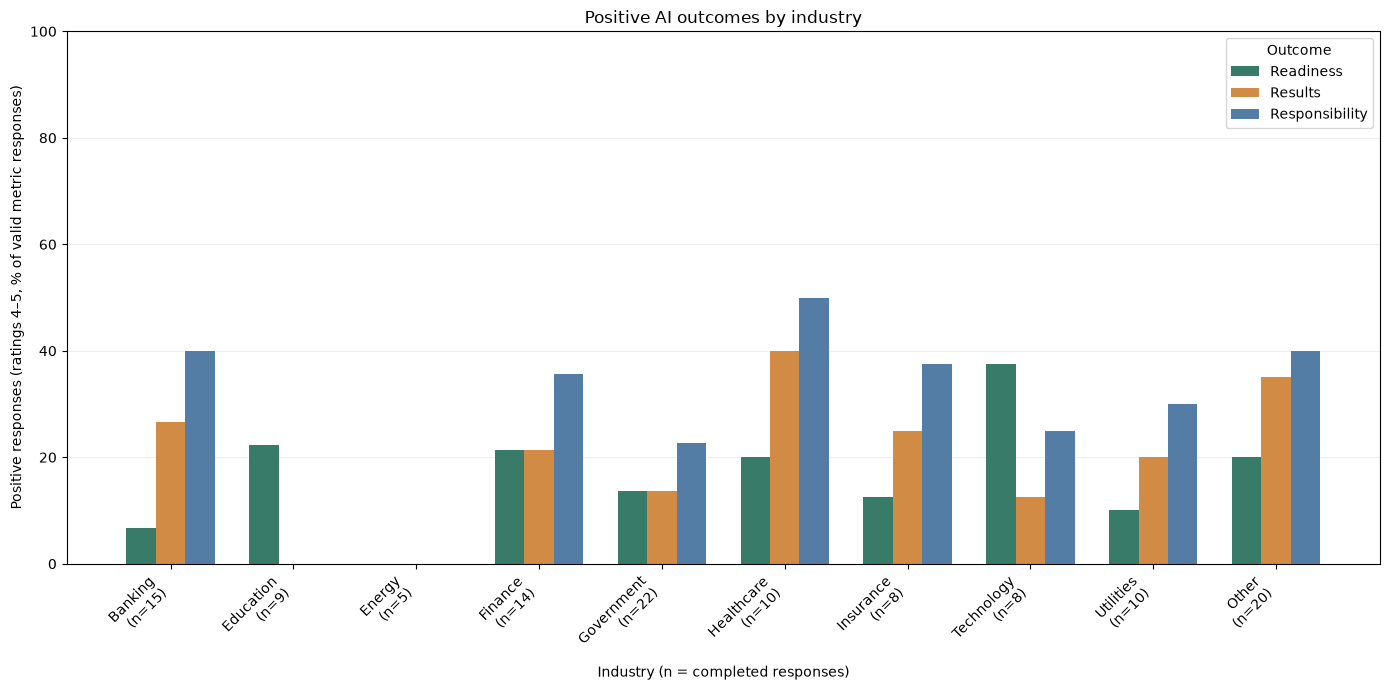

In [ ]:
plot_positive_metrics_by_category(
    completed,
    "industry",
    ai_metric_columns,
    "Positive AI outcomes by industry",
)

## Positive self-assessment outcomes by industry

Grouped bars show the percentage of valid self-assessment responses rated positive (`4` or `5`) within each industry. As in the AI chart above, industries with fewer than 5 completed responses are combined into `Other`. Missing metric responses are excluded from each metric's denominator.

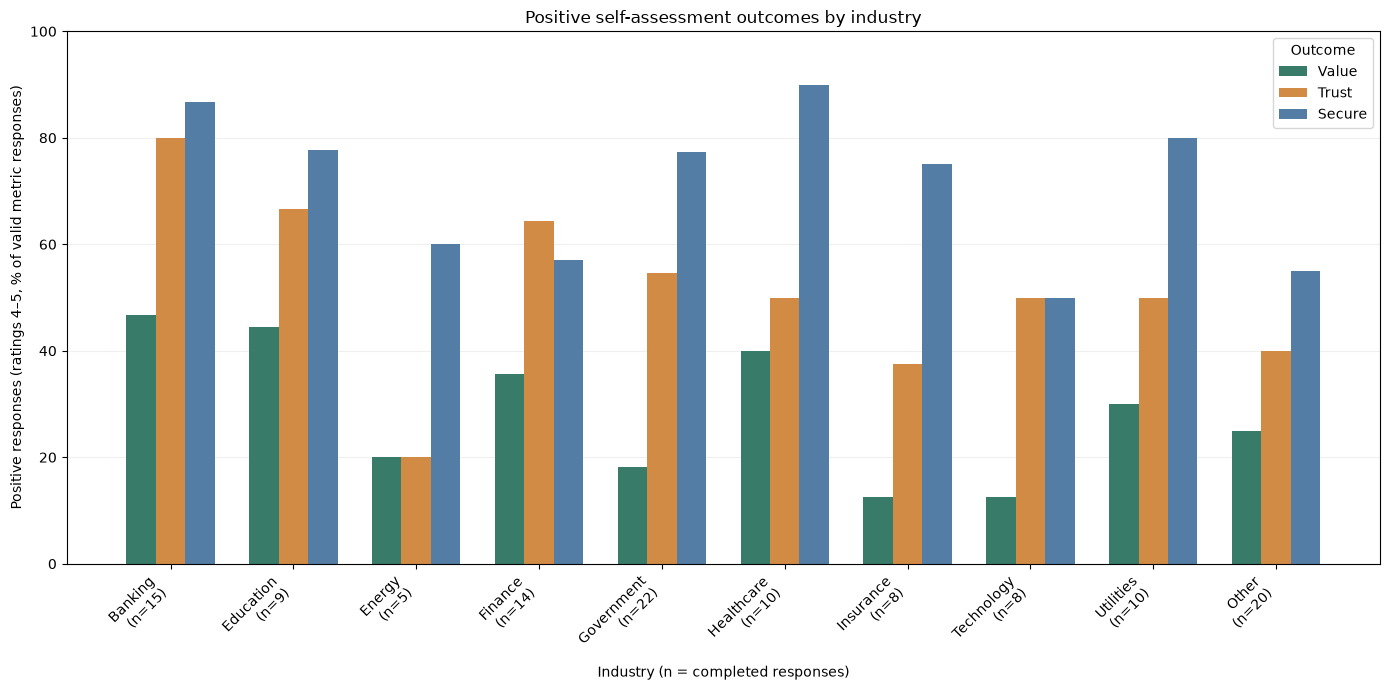

In [ ]:
self_assessment_columns = [
    "self_assess_value",
    "self_assess_trust",
    "self_assess_secure",
]
plot_positive_metrics_by_category(
    completed,
    "industry",
    self_assessment_columns,
    "Positive self-assessment outcomes by industry",
)

## Positive AI outcomes by job role

This chart uses the same grouped-bar calculation as the industry charts. Job roles with fewer than 5 completed responses are pooled into `Other`.

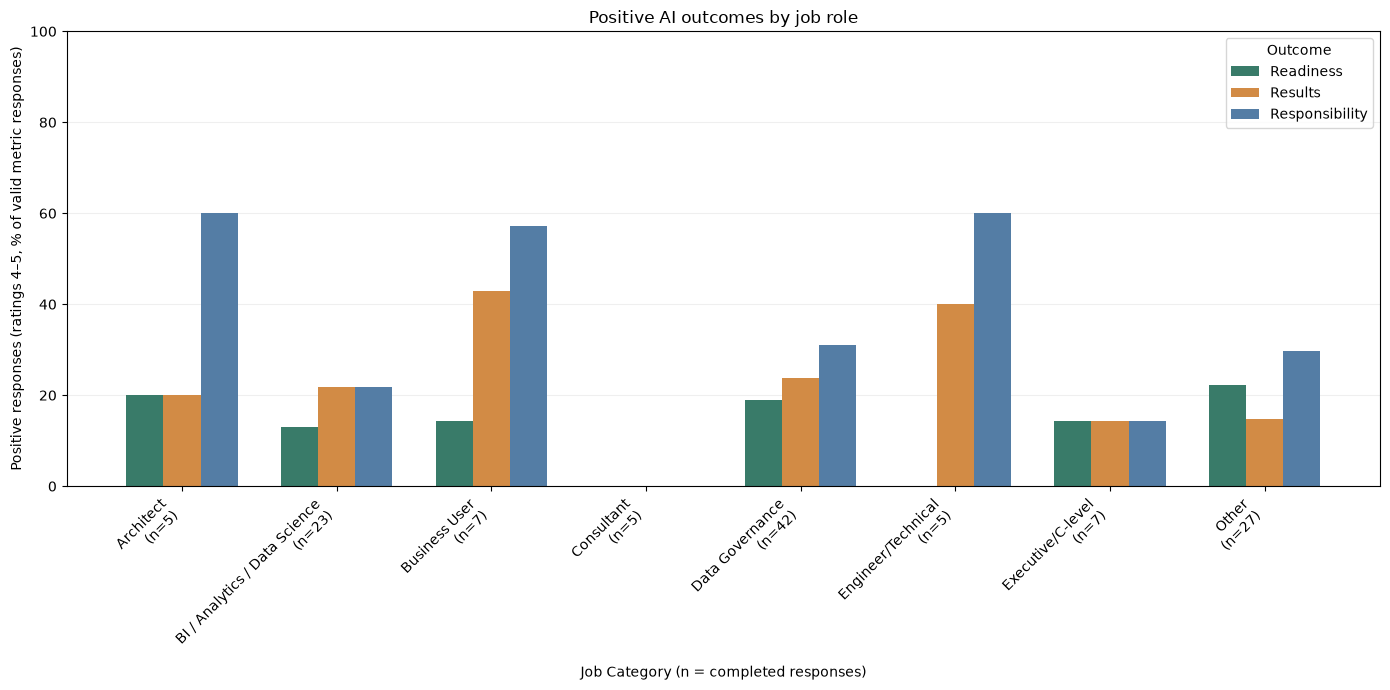

In [ ]:
plot_positive_metrics_by_category(
    completed,
    "job_category",
    ai_metric_columns,
    "Positive AI outcomes by job role",
)

## Positive self-assessment outcomes by job role

This chart uses the same grouped-bar calculation as the other category charts. Job roles with fewer than 5 completed responses are pooled into `Other`.

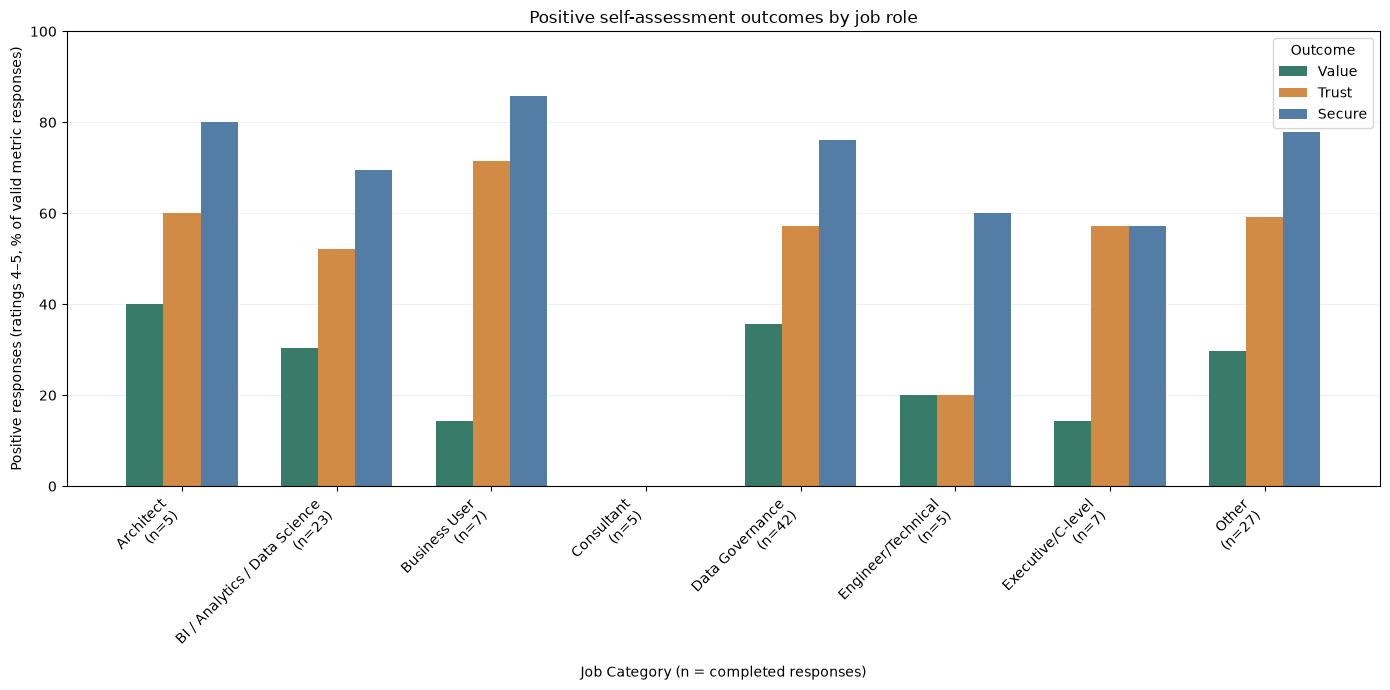

In [ ]:
plot_positive_metrics_by_category(
    completed,
    "job_category",
    self_assessment_columns,
    "Positive self-assessment outcomes by job role",
)